# HR 8799 with amigo 0.1 and the 0.0.10 calibration
HR 8799 (HD 218396) from JWST GTO 1200 (2023-08-03, one F380M exposure), from calslopes to companion fits, with
`amigo-pipeline` and `virgil`. The instrument is the paper's `calibration.npy` (amigo 0.0.10). HR 8799 has four imaged
planets, b, c, d and e, at about 1720, 950, 700 and 400 mas.

The program has no calibrator observation for HR 8799 itself. The calibrator here is HD 93649's F380M exposure from
the same day, taken for HD 95086, which is near it on the sky (roll 152.7°, against HD 95086's 150.2° and HR 8799's
223.0°).

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as np
import numpy as onp

import amigo_pipeline

from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt

load_dict = lambda x: np.load(x, allow_pickle=True).item()

# amigo-pipeline

The first stage of this notebook is to put the calslope data through the amigo-pipeline.

## Loading Data
The calslopes were made from the uncal files with amigo 0.1's `process_calslope` (its defaults, as for the other
`calslope_amigo-0.1` folders), for these two exposures only: HD 95086 and HD 93649's F430M and F480M exposures are not
processed yet.

In [2]:
import os
from amigo.files import get_files

home_path = "/media/morgana1/snert/max/data/"
data_dir = os.path.join(home_path, "JWST/1200/calslope_amigo-0.1/")
output_path = os.path.join(home_path, "pipeline_outputs/hr8799_tauron")

# loading in the calslope files
files = get_files(
    data_dir,
    "calslope",
    EXP_TYPE="NIS_AMI",
    FILTER="F380M",
    TARGPROP=["HD-218396", "HD-93649"],
)
files = sorted(files, key=lambda f: f.filename())

## Instrument calibration
The paper's `calibration.npy`, converted by `convert_calibration_v2.py` with per-visit piston/tip/tilt shared across
filters (`ptt` sharing `program`, which amigo `be7cee0` and later require).

In [3]:
from amigo_pipeline.calibration import load_calibration

# path to saved instrumental state from base model calibration
calibration_path = os.path.join(
    home_path, "amigo_files/v_0.0.11/v2_from_calibration_npy_ptt_program"
)

# dict of model-construction inputs: detector, ramp_model, read, vis_model
# (AmigoModel), opd_calibration (AMIOptics) and defocus (per-filter values)
state = load_calibration(Path(calibration_path))

## Exposures
Exposures of one star, filter and roll share their visibilities (here there is one exposure of each star).

In [4]:
from amigo.model_fits import SplineVisFit
from amigo_pipeline.dataset import visibility_key

roll_tolerance = 1e-3  # degrees; recorded in model_recipe below
groups = {}
exposures = []

for f in files:
    role = "calibrator" if f[0].header["IS_PSF"] else "science"
    vis_key = visibility_key(f[0].header, role, groups, roll_tolerance)
    exposures.append(SplineVisFit(f, vis_key=vis_key))

## Building the model

In [5]:
from amigo_pipeline.dataset import DEFAULT_OPTICS
from amigo.core_models import AmigoModel
from amigo.optical_models import AMIOptics

filters = sorted({exp.filter for exp in exposures})

model = AmigoModel(
    exposures,
    optics=AMIOptics(
        opd_calibration=state["opd_calibration"],
        filters=filters,
        **DEFAULT_OPTICS,
    ),
    detector=state["detector"],
    ramp_model=state["ramp_model"],
    read=state["read"],
    vis_model=state["vis_model"],
)

# setting model defocus
for f in filters:
    model = model.set(f"params.defocus.{f}", np.asarray(state["defocus"][f]))

## Pairs
HR 8799 is calibrated by the HD 93649 exposure, which is also the reference the basis and the null are built at.

In [6]:
pairs = []
for f in filters:
    calibrators = sorted(
        exp.key for exp in exposures if exp.filter == f and exp.calibrator
    )
    visits = {}
    for exp in exposures:
        if exp.filter == f and not exp.calibrator:
            visits.setdefault(exp.vis_key, []).append(exp)
    for visit in visits.values():
        pairs.append(
            {
                "name": f"{visit[0].star}_{f}_obs{visit[0].observation}",
                "science": [exp.key for exp in visit],
                "calibrator": calibrators,
                "reference": calibrators[0],
            }
        )

## Cache provenance
The files the model is built from, and how it is built from them.

In [7]:
from amigo_pipeline.storage import file_hash

# The pipeline keys its cached initial state on these file hashes and this recipe instead
# of the model's raw arrays, so GPU roundoff when rebuilding the model can't invalidate the
# cache: on resume it restores the saved arrays. The recipe must describe everything above
# that decides how the model is built, so update it (or bump "builder") when that changes.
source_files = {
    str(path): file_hash(path)
    for path in [
        *Path(calibration_path).iterdir(),
        *(Path(f.filename()) for f in files),
    ]
    if path.is_file()
}
model_recipe = {
    "builder": "HR8799_pipeline_v0.1",
    "exposures": {"roll_tolerance": roll_tolerance},
    "optics": {**DEFAULT_OPTICS, "filters": filters},
    "vis_model": "PlaceholderVisModel",
}

## Run the pipeline
`run()` resumes: stages already completed in `output` with the same inputs are loaded, not refitted. With
`strict=False`, a completed stage whose inputs differ is reused with a warning instead of raising. A new folder runs
everything, which took about 30 min on tauron's RTX 3090 (2026-11-20).

In [8]:
pipeline = amigo_pipeline.Pipeline(
    exposures,
    model,
    pairs,
    output=output_path,
    roll_tolerance=roll_tolerance,
    source_files=source_files,
    model_recipe=model_recipe,
)
discos, cross = pipeline.run(
    strict=False,
)

assembly/HD-218396_F380M_obs001: cached inputs differ; reusing the cached stage (strict=False)


The pipeline draws its own figures: the instrument fit to HD 93649, HR 8799 fitted as a point source, and the DISCOs.

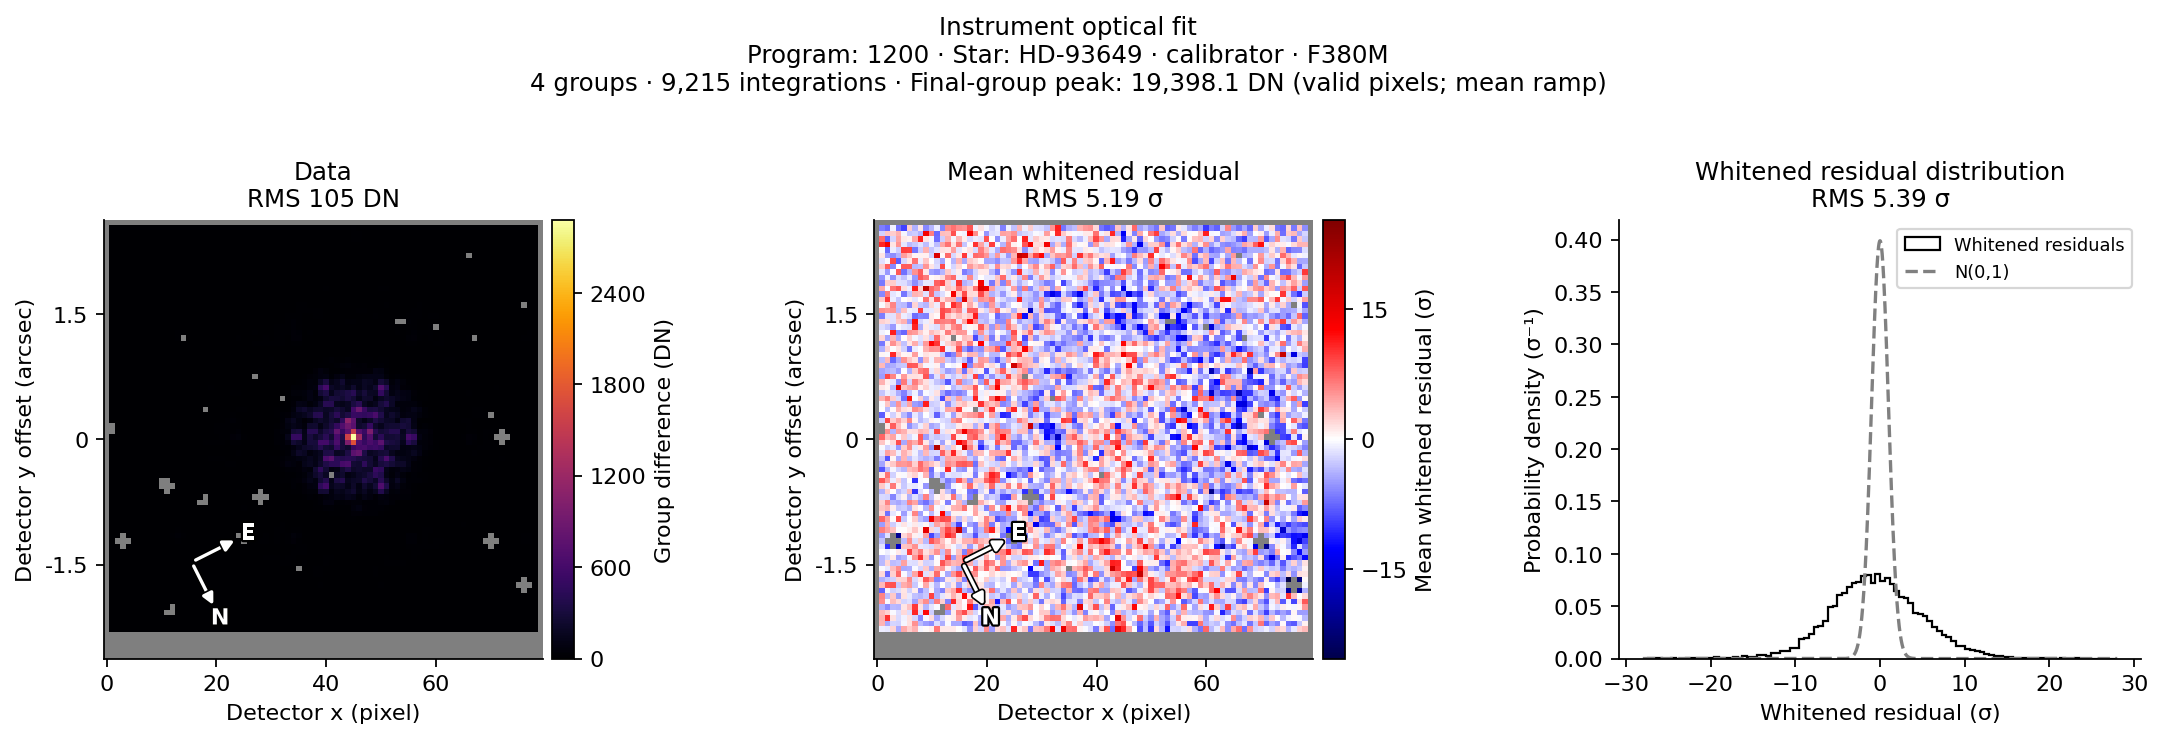

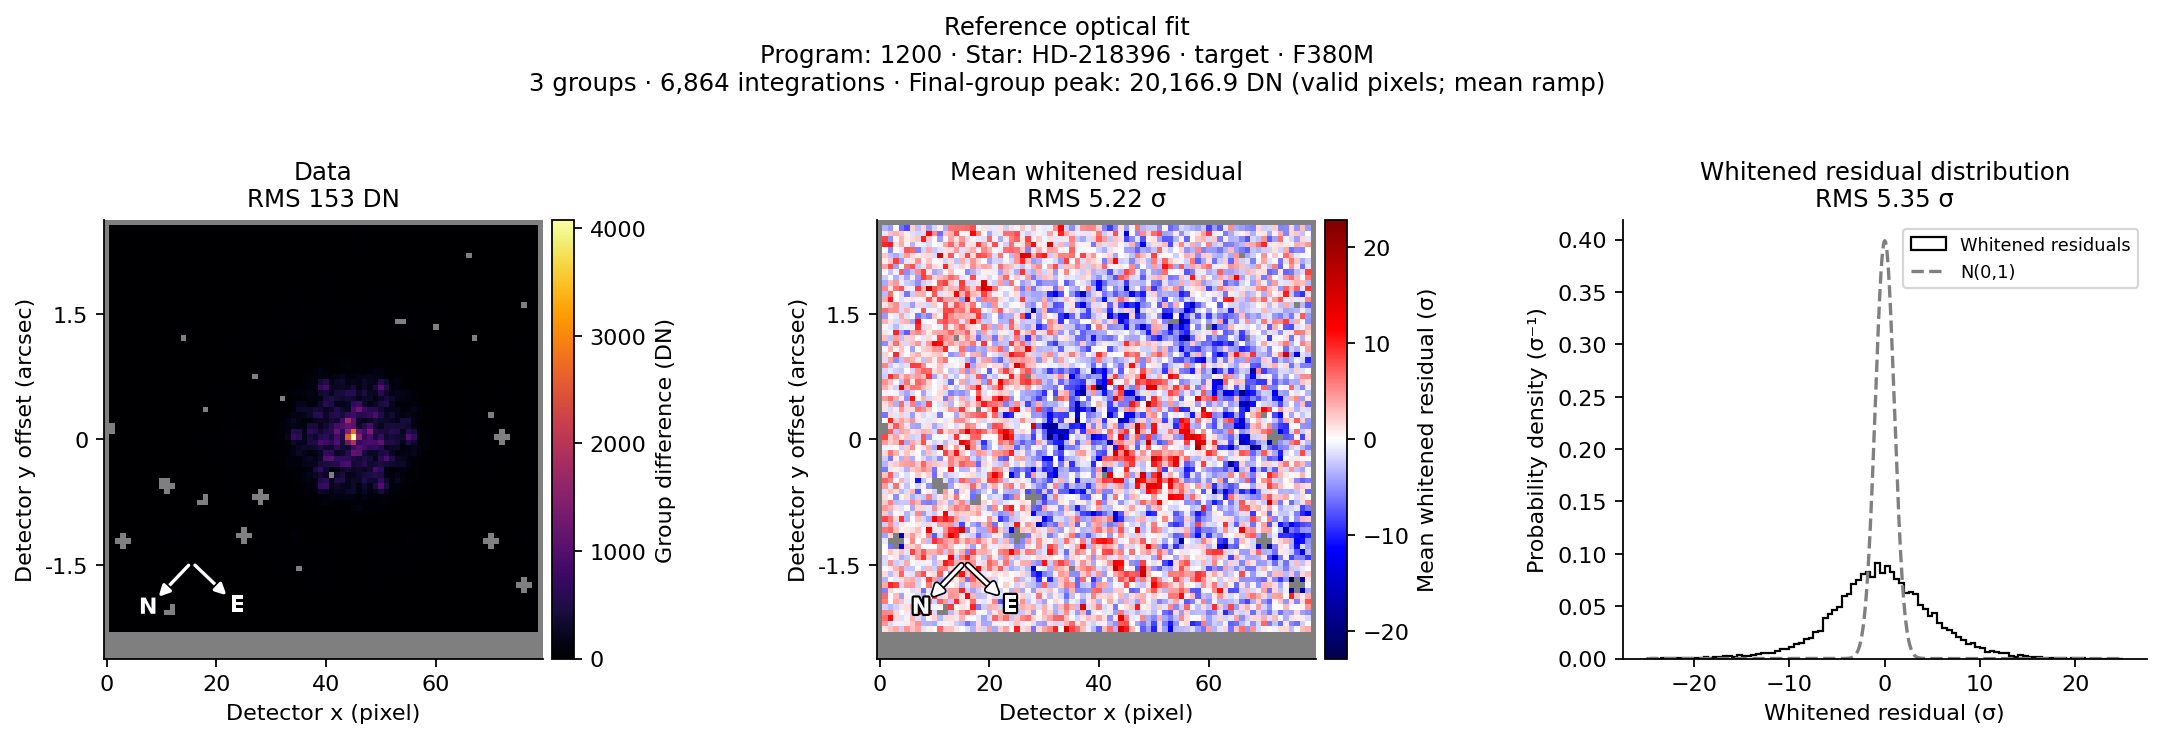

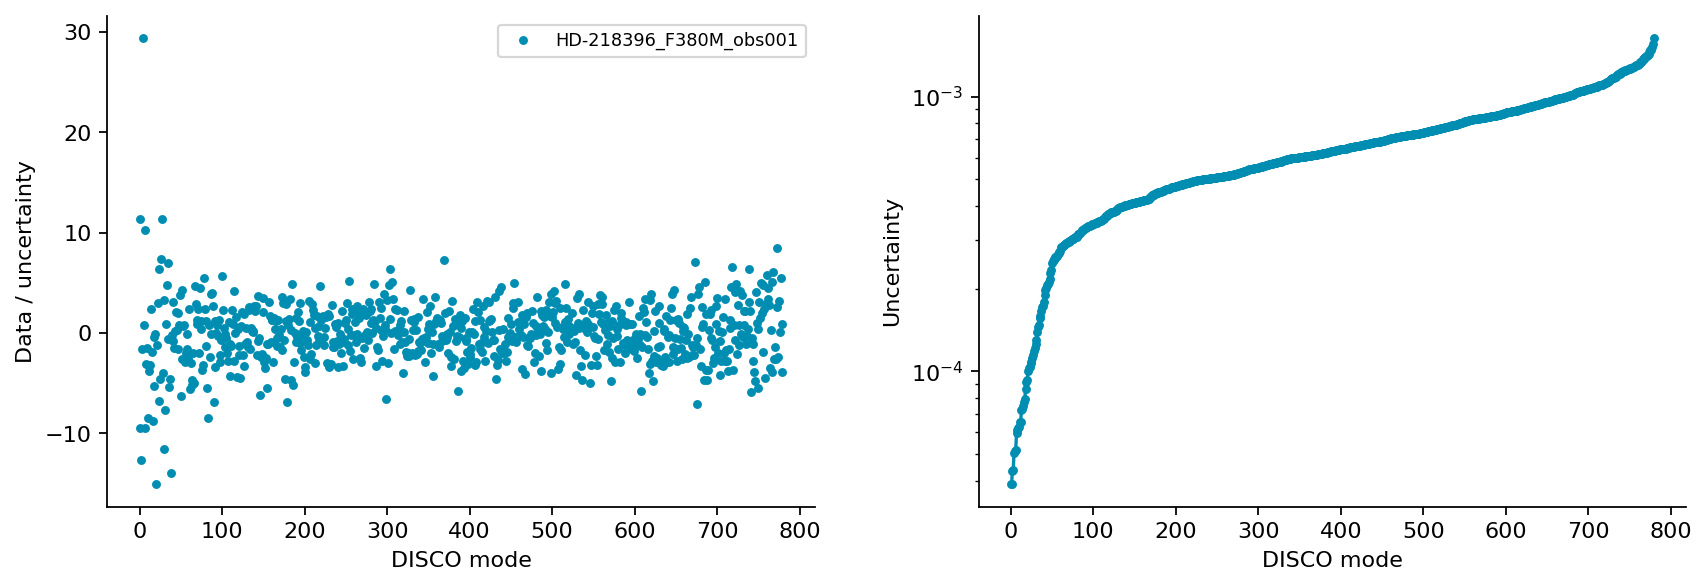

In [9]:
for figure in [
    "instrument/pixels_0.png",
    "reference/pixels_0.png",
    "products/discos.png",
]:
    display(Image(filename=str(Path(output_path) / figure)))

## How the fits went
Every pipeline fit, one row per exposure. `residual_rms_sigma` is the RMS of the whitened detector residuals, so 1
means the fit reaches the noise and larger values are model error (or underestimated noise). `gradient` is the largest
normalised gradient at the end of the fit (the acceptance threshold is 1e-6).

In [10]:
import sys

sys.path.insert(0, "..")  # pipeline_plots.py, shared with the 0.2 notebooks
import pipeline_plots

pipeline_plots.fit_summary(output_path).round({"residual_rms_sigma": 2, "minutes": 1})

filter        role  residual_rms_sigma  \
stage      exposure                                                   
instrument 01200_003_04_03_1  F380M  calibrator                5.39   
reference  01200_001_02_03_1  F380M      target                5.35   
visibility 01200_001_02_03_1  F380M      target                4.21   
           01200_003_04_03_1  F380M  calibrator                4.57   

                                       status      gradient  minutes  
stage      exposure                                                   
instrument 01200_003_04_03_1  gradient_target  1.116279e-07      2.4  
reference  01200_001_02_03_1  gradient_target  5.154719e-07      1.3  
visibility 01200_001_02_03_1  gradient_target  4.329073e-07      4.6  
           01200_003_04_03_1  gradient_target  5.125012e-08      4.6

Whitened detector residuals for both exposures, from the point-source fit (HD 93649: instrument stage; HR 8799:
reference stage) and from the visibility fit. Structure that survives the visibility fit is not explained by the
visibility basis.

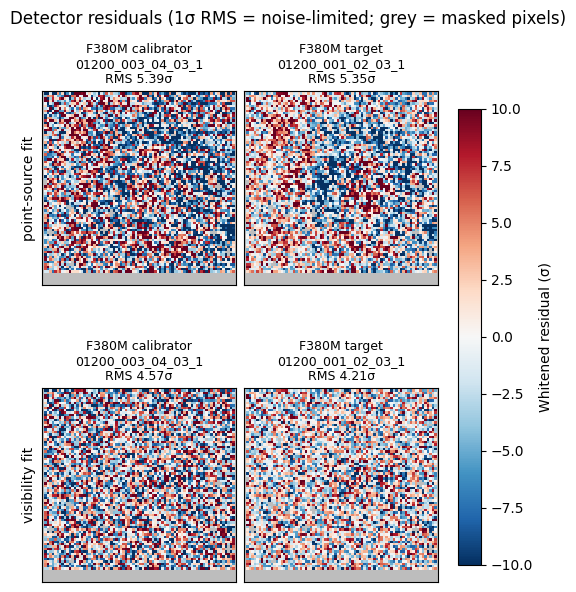

In [11]:
pipeline_plots.residual_grid(output_path)
plt.show()

## Visibilities in the uv plane
Each fit's visibility coefficients times the basis modes give the log-visibility it fitted on the uv grid, relative to
the optical model. Science and calibrator share a colour scale, so the instrument signature they have in common is
visible; the calibrated column (science minus calibrator) is what goes into the DISCOs. Axes are in the instrument
frame, not on the sky.

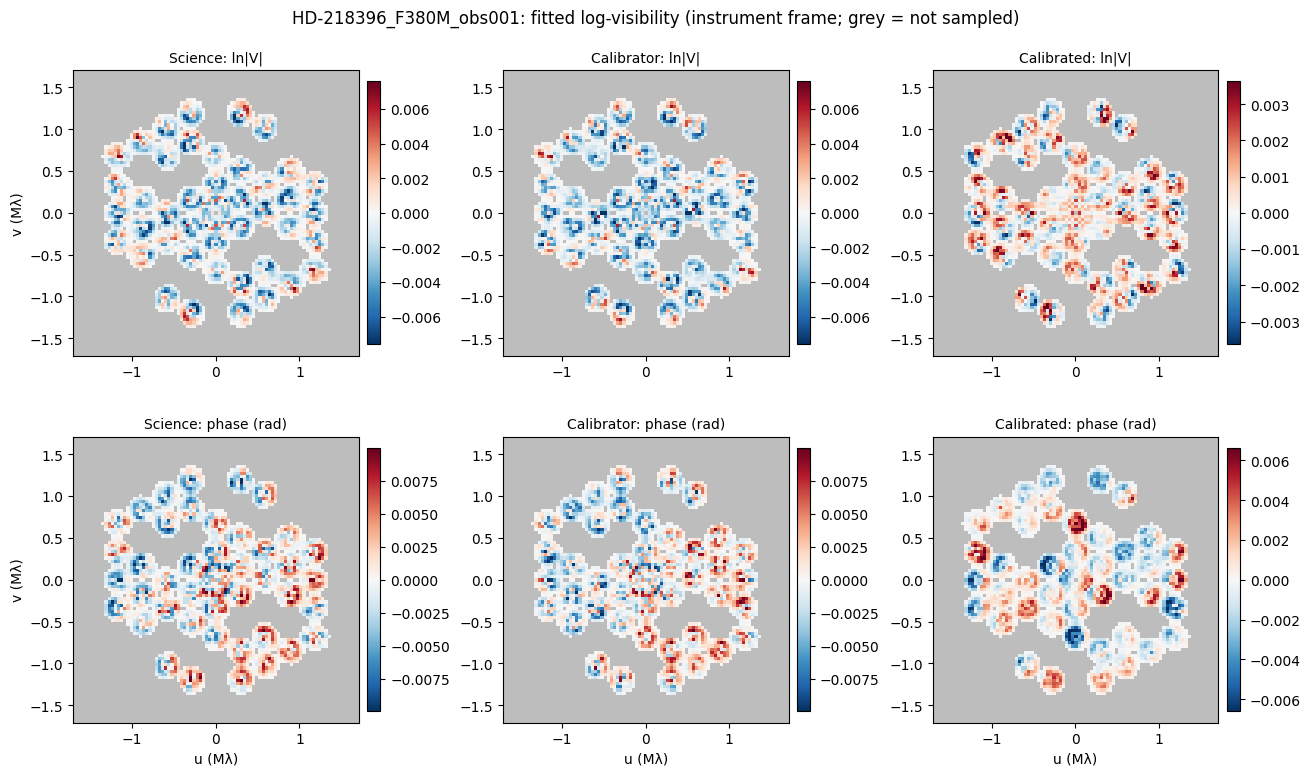

In [12]:
for name, disco in discos.items():
    pipeline_plots.uv_visibilities(output_path, name, disco)
    plt.show()

# virgil

## The planets' positions
The four planets on 2023-08-03, from GRAVITY (unpublished; as listed in `../../HR8799_astrometry.ipynb`). PA is east of
north, Virgil's convention, throughout.

In [13]:
from virgil.grid_fit import likelihood_grid
from virgil.likelihood import model_loglike, whitened_residuals
from virgil.models import PointSource, System
from virgil.pipeline import BinaryPipeline

from amigo.discos import to_virgil

import pandas as pd
import scipy  # for minimize


def offsets(sep, pa_deg):
    th = onp.radians(pa_deg)
    return sep * onp.sin(th), sep * onp.cos(th)


gravity = pd.DataFrame(
    {
        "b": (1719.929, 71.968),
        "c": (954.378, 342.398),
        "d": (697.598, 240.339),
        "e": (399.834, 324.593),
    },
    index=["sep_mas", "pa_deg"],
).T
gravity["dra_mas"], gravity["ddec_mas"] = offsets(gravity["sep_mas"], gravity["pa_deg"])
gravity.round(1)

/home/max/conda/miniconda3/envs/0.1/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,sep_mas,pa_deg,dra_mas,ddec_mas
b,1719.9,72.0,1635.5,532.4
c,954.4,342.4,-288.6,909.7
d,697.6,240.3,-606.2,-345.2
e,399.8,324.6,-231.7,325.9


## One companion
Virgil's binary pipeline on the DISCOs. It fits a single companion, so it finds the strongest signal. The search
reaches 2000 mas to take in all four planets; the DISCO samples lie on a uv lattice whose first alias in F380M is at
about 2560 mas, so that box has no alias copies.

If the fit's reduced χ² is above 1 with the errors as quoted, the quoted errors are too small; the `x √χ²` columns
scale them up to make χ²/dof = 1 (a rough correction: it assumes the excess scatter is white). `nearest` is the
closest GRAVITY planet and `offset_mas` the distance to it.

`detection_sigma` is the local significance of the companion: √Δχ² for one more point source at a position fixed in
advance, with no look-elsewhere correction. `detection_sigma_scaled` divides Δχ² by the reduced χ² first, the same
rough correction as the `x √χ²` columns. Virgil's `local_nsigma` is the same number but stops at about 37.5σ, where
float64 runs out of tail probability.

In [14]:
results = {
    name: BinaryPipeline(
        to_virgil(disco),
        output=Path(output_path) / "binary" / name,
        max_sep_mas=2000.0,
        max_grid=161,  # 25 mas steps, as in the search below
        n_flux=80,
    ).run()
    for name, disco in discos.items()
}


def nearest(dra, ddec):
    distance = onp.hypot(gravity["dra_mas"] - dra, gravity["ddec_mas"] - ddec)
    return distance.idxmin(), distance.min()


rows = {}
for name, res in results.items():
    c, s = res.summary["companion"], res.summary["chi2"]
    k = onp.sqrt(s["companion_reduced"])
    dchi2 = max(res.summary["search"]["delta_chi2"], 0.0)
    planet, offset = nearest(c["dra_mas"], c["ddec_mas"])
    rows[name.split("_")[1]] = {
        "sep_mas": c["sep_mas"],
        "sep_err": c["sep_err_mas"],
        "sep_err_x_sqrt_chi2": k * c["sep_err_mas"],
        "pa_deg": c["pa_deg"],
        "pa_err": c["pa_err_deg"],
        "pa_err_x_sqrt_chi2": k * c["pa_err_deg"],
        "delta_mag": c["delta_mag"],
        "chi2_reduced": s["companion_reduced"],
        "detection_sigma": onp.sqrt(dchi2),
        "detection_sigma_scaled": onp.sqrt(dchi2 / s["companion_reduced"]),
        "nearest": planet,
        "offset_mas": offset,
    }
pd.DataFrame.from_dict(rows, orient="index").round(2)

,sep_mas,sep_err,sep_err_x_sqrt_chi2,pa_deg,pa_err,pa_err_x_sqrt_chi2,delta_mag,chi2_reduced,detection_sigma,detection_sigma_scaled,nearest,offset_mas
F380M,379.7,3.88,11.38,322.86,0.61,1.78,8.21,8.61,25.38,8.65,e,23.32


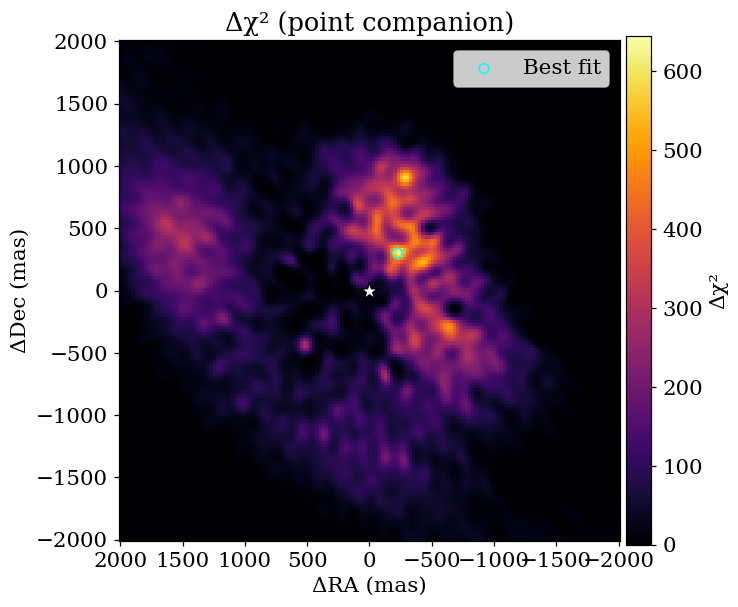

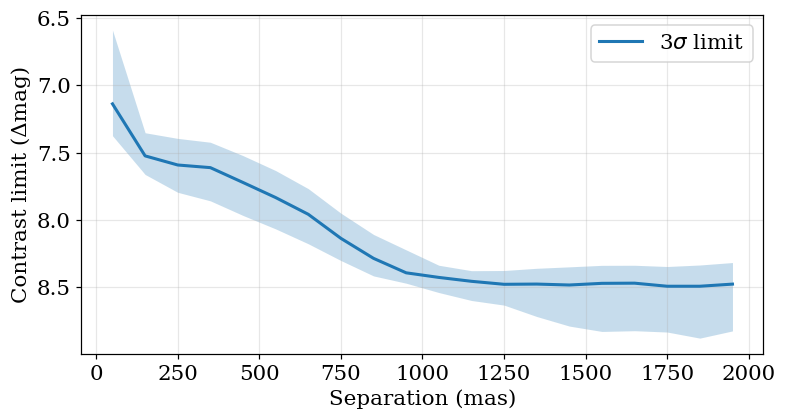

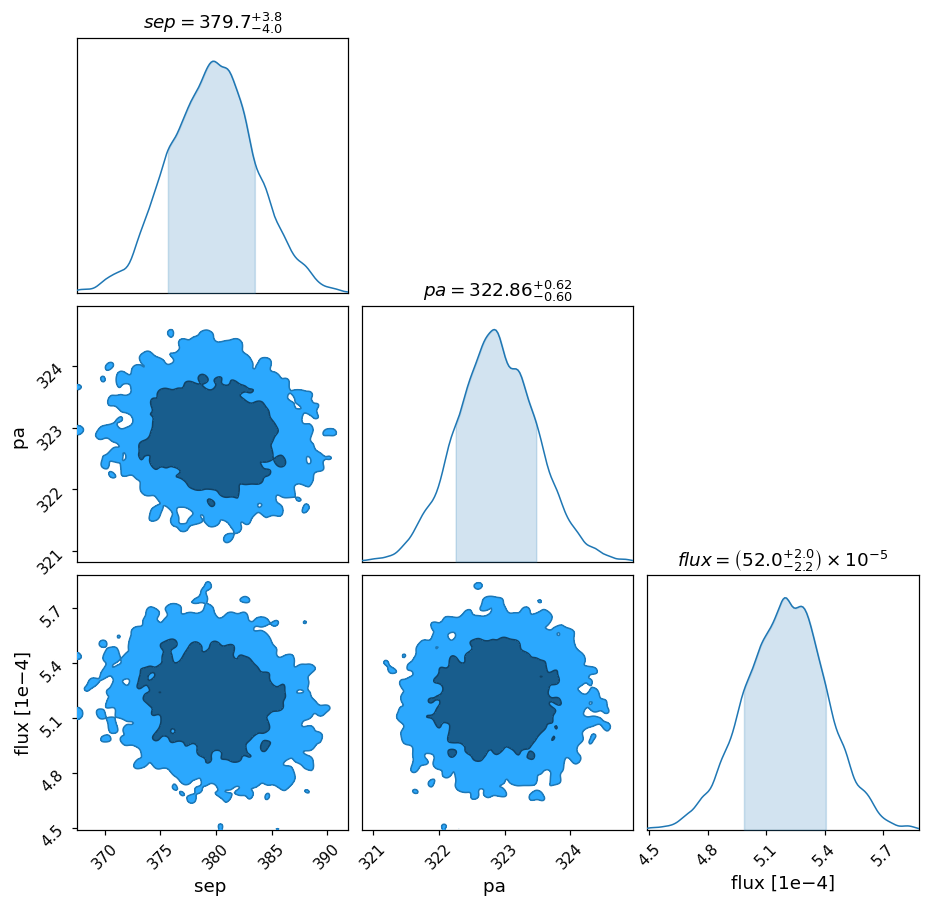

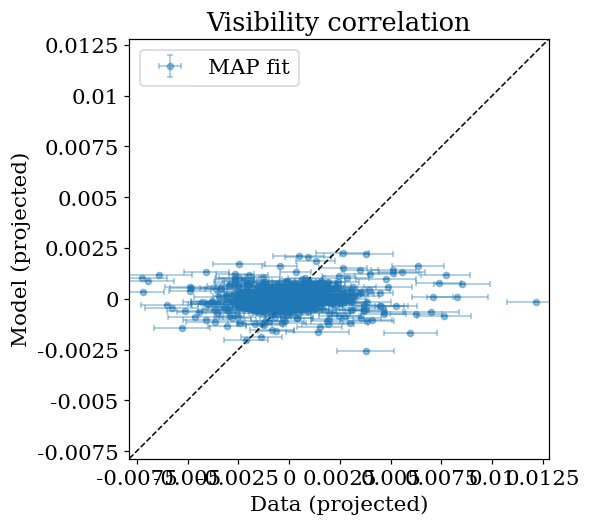

In [15]:
plots = Path(output_path) / "binary" / next(iter(results)) / "plots"
for plot in [
    "search_delta_chi2",
    "limits_contrast_curve",
    "posterior_corner",
    "fit_correlation",
]:
    display(Image(filename=str(plots / f"{plot}.png")))

Calibrated visibilities against the best-fit binary, drawn in the uv plane in units of σ. Both are projected the same
way as the DISCOs, so this is the comparison Virgil fits, laid out in uv. Neighbouring uv points are correlated, so
the residual RMS is a guide rather than a χ²; the reduced χ² is in the table above.

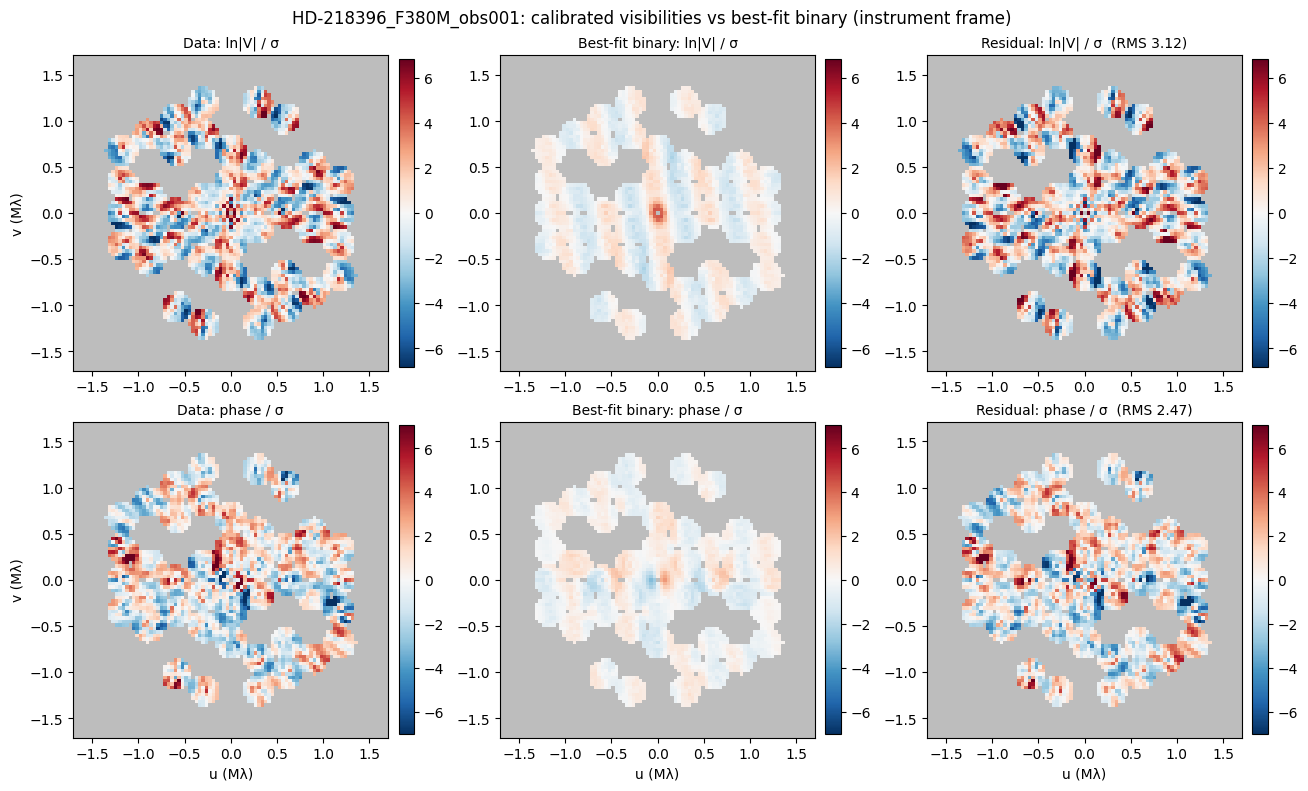

In [16]:
for name, disco in discos.items():
    c = results[name].summary["companion"]
    binary = System(
        star=PointSource(),
        companion=PointSource(flux=c["flux"], dra=c["dra_mas"], ddec=c["ddec_mas"]),
    )
    pipeline_plots.uv_model_comparison(
        output_path, name, disco, binary, label="best-fit binary"
    )
    plt.show()

## More companions, one at a time
Each step holds the companions found so far and maps the improvement in χ² from one more point source over a grid of
positions and fluxes, at the best flux in each position. The map's peak is added, and then all the companions are
fitted together (positions and log fluxes free); the first step starts from the binary fit above. It stops at four
companions, or when the peak Δχ² divided by the current fit's reduced χ² (the same rough correction as the √χ² error
scaling) falls below 25. The map covers about 25,000 positions, so a peak needs well over the single-trial Δχ² for a
given significance, and structured residuals can pass too. Tried on HD 206893's F430M DISCO in a ±400 mas box, the
search found B, then a source at 386 mas (scaled Δχ² 36) that matches no known companion, and stopped at c (19), which
the fit at the known positions below does detect (30). Circles mark the GRAVITY positions, crosses the companions
held, and the plus the peak.

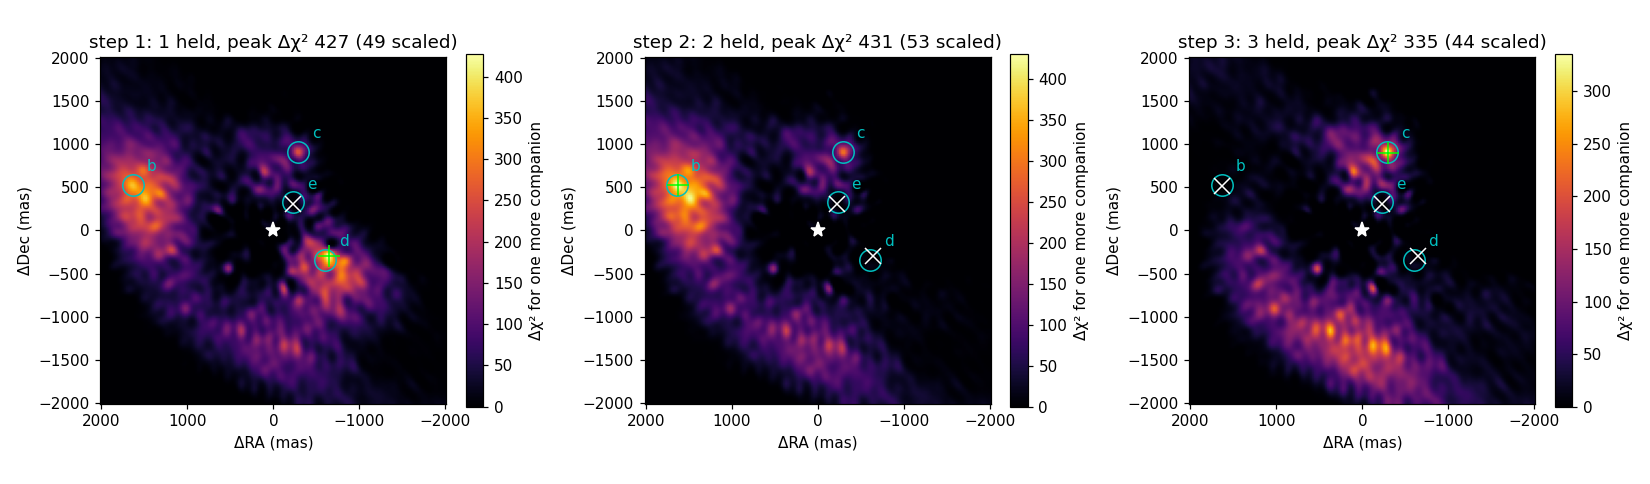

In [17]:
axis = onp.arange(-2000.0, 2001.0, 25.0)  # mas
fluxes = onp.geomspace(1e-5, 3e-3, 30)  # companion / star
n_max, min_dchi2 = 4, 25.0


def scene(x, **extra):
    """The star plus one point source per row of x: (dra, ddec) in mas and log flux."""
    sources = {
        f"p{i}": PointSource(flux=np.exp(f), dra=a, ddec=d)
        for i, (a, d, f) in enumerate(x)
    }
    return System(star=PointSource(), **sources, **extra)


def joint_fit(data, x0):
    """All companions together from x0, shape (n, 3): best x, covariance, χ² and log likelihood."""
    x0 = onp.asarray(x0, float).reshape(-1, 3)
    loss = lambda v: -model_loglike(scene(v.reshape(x0.shape)), data)
    nll, grad = jax.jit(loss), jax.jit(jax.grad(loss))
    r = scipy.optimize.minimize(
        lambda v: float(nll(v)),
        x0.ravel(),
        jac=lambda v: onp.asarray(grad(v)),
        method="BFGS",
    )
    cov = onp.linalg.inv(onp.asarray(jax.hessian(loss)(r.x)))
    x = r.x.reshape(x0.shape)
    chi2 = float(onp.sum(onp.asarray(whitened_residuals(scene(x), data)) ** 2))
    return {"x": x, "cov": cov, "chi2": chi2, "ll": -float(r.fun)}


searches = {}
for name, disco in discos.items():
    data = to_virgil(disco)
    c = results[name].summary["companion"]
    n_independent = results[name].summary["chi2"]["n_independent"]
    fit = joint_fit(data, [c["dra_mas"], c["ddec_mas"], onp.log(c["flux"])])
    steps = []
    while len(fit["x"]) < n_max:
        template = scene(fit["x"], trial=PointSource(flux=1e-4, dra=0.0, ddec=0.0))
        ll = onp.asarray(
            likelihood_grid(
                template,
                data=data,
                grid={"trial.dra": axis, "trial.ddec": axis, "trial.flux": fluxes},
            )
        )
        dchi2 = 2 * (ll.max(-1) - fit["ll"])  # (dra, ddec)
        i, j = onp.unravel_index(onp.argmax(dchi2), dchi2.shape)
        chi2_red = fit["chi2"] / (n_independent - 3 * len(fit["x"]))
        steps.append(
            {
                "held": fit["x"],
                "dchi2": dchi2,
                "peak": (axis[i], axis[j], dchi2[i, j]),
                "chi2_red": chi2_red,
            }
        )
        if dchi2[i, j] / chi2_red < min_dchi2:
            break
        trial = [axis[i], axis[j], onp.log(fluxes[ll[i, j].argmax()])]
        fit = joint_fit(data, onp.vstack([fit["x"], trial]))
    searches[name] = {"data": data, "fit": fit, "steps": steps}

for name, s in searches.items():
    steps, half = s["steps"], (axis[1] - axis[0]) / 2
    fig, axes = plt.subplots(
        1, len(steps), figsize=(5 * len(steps), 4.4), squeeze=False
    )
    for n, (ax, step) in enumerate(zip(axes[0], steps)):
        m = ax.imshow(
            step["dchi2"].T,
            origin="lower",
            cmap="inferno",
            vmin=0,
            extent=[axis[0] - half, axis[-1] + half, axis[0] - half, axis[-1] + half],
        )
        ax.invert_xaxis()  # east to the left
        for planet, row in gravity.iterrows():
            ax.plot(row["dra_mas"], row["ddec_mas"], "o", mfc="none", mec="c", ms=14)
            ax.annotate(
                planet,
                (row["dra_mas"], row["ddec_mas"]),
                color="c",
                xytext=(9, 9),
                textcoords="offset points",
            )
        ax.plot(step["held"][:, 0], step["held"][:, 1], "x", c="w", ms=10)
        ax.plot(*step["peak"][:2], "+", c="lime", ms=14)
        ax.plot(0, 0, "*", c="w", ms=10)
        ax.set(
            title=f"step {n + 1}: {len(step['held'])} held, peak Δχ² {step['peak'][2]:.0f}"
            f" ({step['peak'][2] / step['chi2_red']:.0f} scaled)",
            xlabel="ΔRA (mas)",
            ylabel="ΔDec (mas)",
        )
        plt.colorbar(m, ax=ax, fraction=0.046, label="Δχ² for one more companion")
    fig.tight_layout()
    path = Path(output_path) / "binary" / f"search_steps_{name}.png"
    fig.savefig(path, dpi=110)
    plt.close(fig)
    display(Image(filename=str(path)))

The companions found, from the final joint fit, in the order they were found. `dchi2_without` is how much worse the
fit gets when that companion is removed and the others refitted, and `dchi2_without_scaled` is that divided by the
reduced χ². Errors come from the curvature at the best fit, quoted and scaled by √χ²/dof as above.

(2026-11-20: the search found e, d, b and c, in that order, each within 64 mas of its GRAVITY position and each with
scaled Δχ² 45–78 when removed. The reduced χ² only falls from 8.6 with one companion to 7.1 with four. The maps also
show a broad band of Δχ² 100–300 through b and d, and with b, d and e held the third map still reaches about 250 near
ΔRA +600, ΔDec −1200 mas, where no planet is known, against c's 335. So these significances lean on the rough √χ²
correction.)

In [18]:
def polar(x, cov, k):
    dra, ddec = x[k], x[k + 1]
    sep, pa = onp.hypot(dra, ddec), onp.degrees(onp.arctan2(dra, ddec)) % 360
    J = onp.array(
        [
            [dra / sep, ddec / sep],
            [onp.degrees(ddec / sep**2), -onp.degrees(dra / sep**2)],
        ]
    )
    C = J @ cov[k : k + 2, k : k + 2] @ J.T
    return (
        sep,
        onp.sqrt(C[0, 0]),
        pa,
        onp.sqrt(C[1, 1]),
        -2.5 * x[k + 2] / onp.log(10),
        2.5 / onp.log(10) * onp.sqrt(cov[k + 2, k + 2]),
    )


def without(data, x, i):
    """Best log likelihood with companion i removed and the others refitted."""
    rest = onp.delete(x, i, axis=0)
    if len(rest) == 0:
        return float(model_loglike(System(star=PointSource()), data))
    return joint_fit(data, rest)["ll"]


def companion_table(data, fit, n_independent):
    x, n = fit["x"], len(fit["x"])
    chi2_red = fit["chi2"] / (n_independent - 3 * n)
    rows = {}
    for i in range(n):
        sep, dsep, pa, dpa, dmag, ddmag = polar(x.ravel(), fit["cov"], 3 * i)
        planet, offset = nearest(x[i, 0], x[i, 1])
        dchi2 = 2 * (fit["ll"] - without(data, x, i))
        rows[i + 1] = {
            "sep_mas": sep,
            "sep_err": dsep,
            "sep_err_x_sqrt_chi2": onp.sqrt(chi2_red) * dsep,
            "pa_deg": pa,
            "pa_err": dpa,
            "pa_err_x_sqrt_chi2": onp.sqrt(chi2_red) * dpa,
            "delta_mag": dmag,
            "dmag_err": ddmag,
            "dchi2_without": dchi2,
            "dchi2_without_scaled": dchi2 / chi2_red,
            "nearest": planet,
            "offset_mas": offset,
            "chi2_reduced": chi2_red,
        }
    return pd.DataFrame.from_dict(rows, orient="index")


pd.concat(
    {
        name.split("_")[1]: companion_table(
            s["data"], s["fit"], results[name].summary["chi2"]["n_independent"]
        )
        for name, s in searches.items()
    },
    names=["filter", "found"],
).round(2)

sep_mas  sep_err  sep_err_x_sqrt_chi2  pa_deg  pa_err  \
filter found                                                          
F380M  1       369.02     4.58                12.19  323.65    0.71   
       2       703.03     5.00                13.32  245.54    0.42   
       3      1714.47     8.16                21.74   72.23    0.25   
       4       951.90     4.21                11.22  342.53    0.25   

              pa_err_x_sqrt_chi2  delta_mag  dmag_err  dchi2_without  \
filter found                                                           
F380M  1                    1.90       8.51      0.06         317.49   
       2                    1.13       8.75      0.05         556.51   
       3                    0.65       9.02      0.05         484.66   
       4                    0.66       9.15      0.05         397.69   

              dchi2_without_scaled nearest  offset_mas  chi2_reduced  
filter found                                                          
F380M  1                     44.77       e       31.45          7.09  
       2                     78.47       d       63.78          7.09  
       3                     68.34       b        9.68          7.09  
       4                     56.08       c        3.36          7.09

## The planets at their GRAVITY positions
First the four planets' fluxes with their positions held at GRAVITY's, fitted together and kept non-negative.
`dchi2_without` is how much worse that fit gets without the planet (the other fluxes refitted), so it measures each
planet's signal at its known position, with no search; `dchi2_without_scaled` divides it by the reduced χ² of the
four-planet fit. Then the planets with `dchi2_without_scaled` above 25 are fitted together with their positions free,
starting from GRAVITY's.

In [19]:
def flux_fit(data, positions):
    """Fluxes (companion / star, ≥ 0) of point sources held at positions (n, 2) in mas."""
    positions = onp.asarray(positions, float).reshape(-1, 2)
    scale = 1e-4  # fitted in units of 1e-4 to keep the optimiser well scaled

    def held(y):
        sources = {
            f"p{i}": PointSource(flux=scale * y[i], dra=a, ddec=d)
            for i, (a, d) in enumerate(positions)
        }
        return System(star=PointSource(), **sources)

    def chi2(y):
        return float(onp.sum(onp.asarray(whitened_residuals(held(y), data)) ** 2))

    if len(positions) == 0:
        star = held(onp.zeros(0))
        return (
            onp.zeros(0),
            float(model_loglike(star, data)),
            onp.zeros(0),
            chi2(onp.zeros(0)),
        )
    loss = lambda y: -model_loglike(held(y), data)

    nll, grad = jax.jit(loss), jax.jit(jax.grad(loss))
    r = scipy.optimize.minimize(
        lambda y: float(nll(y)),
        onp.ones(len(positions)),
        jac=lambda y: onp.asarray(grad(y)),
        method="L-BFGS-B",
        bounds=[(0.0, 1e3)] * len(positions),
    )
    errors = onp.sqrt(onp.diag(onp.linalg.inv(onp.asarray(jax.hessian(loss)(r.x)))))
    return scale * r.x, -float(r.fun), scale * errors, chi2(r.x)


forced, free = {}, {}
for name, s in searches.items():
    data, filt = s["data"], name.split("_")[1]
    positions = gravity[["dra_mas", "ddec_mas"]].to_numpy()
    flux, ll, flux_err, chi2 = flux_fit(data, positions)
    chi2_red = chi2 / (results[name].summary["chi2"]["n_independent"] - len(positions))
    for i, planet in enumerate(gravity.index):
        dchi2 = 2 * (ll - flux_fit(data, onp.delete(positions, i, axis=0))[1])
        forced[(filt, planet)] = {
            "flux": flux[i],
            "flux_err": flux_err[i],
            "delta_mag": -2.5 * onp.log10(flux[i]) if flux[i] > 0 else onp.inf,
            "dchi2_without": dchi2,
            "dchi2_without_scaled": dchi2 / chi2_red,
        }
    detected = [
        p
        for p in gravity.index
        if forced[(filt, p)]["dchi2_without_scaled"] > min_dchi2
    ]
    if detected:
        start = [
            [
                gravity.loc[p, "dra_mas"],
                gravity.loc[p, "ddec_mas"],
                onp.log(forced[(filt, p)]["flux"]),
            ]
            for p in detected
        ]
        free[name] = (detected, joint_fit(data, start))
pd.DataFrame(forced).T.rename_axis(["filter", "planet"]).astype(float).round(
    {
        "flux": 6,
        "flux_err": 6,
        "delta_mag": 2,
        "dchi2_without": 1,
        "dchi2_without_scaled": 1,
    }
)

flux  flux_err  delta_mag  dchi2_without  \
filter planet                                                 
F380M  b       0.000246  0.000011       9.02          479.0   
       c       0.000209  0.000011       9.20          360.5   
       d       0.000288  0.000013       8.85          485.9   
       e       0.000365  0.000021       8.60          294.2   

               dchi2_without_scaled  
filter planet                        
F380M  b                       66.6  
       c                       50.1  
       d                       67.5  
       e                       40.9

The detected planets with their positions free. `dsep_mas` and `dpa_deg` are this fit minus GRAVITY, and `offset_mas`
is the distance between the two positions.

(2026-11-20, against GRAVITY's positions from the same night: b and c agree to within 10 mas. d is 5.2° off in PA
(4.6σ with the scaled errors) and e 31 mas inside in separation (2.5σ). With all four planets the residual RMS (3.0σ
in log amplitude, 2.4σ in phase) is about that of the data, so the planets account for little of the calibrated
signal.)

In [20]:
tables = {}
for name, (detected, fit) in free.items():
    n_independent = results[name].summary["chi2"]["n_independent"]
    table = companion_table(searches[name]["data"], fit, n_independent)
    table.index = detected
    table["dsep_mas"] = table["sep_mas"] - gravity.loc[detected, "sep_mas"]
    table["dpa_deg"] = (
        table["pa_deg"] - gravity.loc[detected, "pa_deg"] + 180
    ) % 360 - 180
    table["offset_mas"] = onp.hypot(
        fit["x"][:, 0] - gravity.loc[detected, "dra_mas"],
        fit["x"][:, 1] - gravity.loc[detected, "ddec_mas"],
    )
    tables[name.split("_")[1]] = table.drop(columns="nearest")
if tables:
    display(pd.concat(tables, names=["filter", "planet"]).astype(float).round(2))
else:
    print(
        f"No planet has dchi2_without_scaled above {min_dchi2:.0f} at its GRAVITY position."
    )

sep_mas  sep_err  sep_err_x_sqrt_chi2  pa_deg  pa_err  \
filter planet                                                          
F380M  b       1714.47     8.16                21.74   72.23    0.25   
       c        951.90     4.21                11.22  342.53    0.25   
       d        703.03     5.00                13.32  245.54    0.42   
       e        369.02     4.58                12.19  323.65    0.71   

               pa_err_x_sqrt_chi2  delta_mag  dmag_err  dchi2_without  \
filter planet                                                           
F380M  b                     0.65       9.02      0.05         484.66   
       c                     0.66       9.15      0.05         397.69   
       d                     1.13       8.75      0.05         556.51   
       e                     1.90       8.51      0.06         317.49   

               dchi2_without_scaled  offset_mas  chi2_reduced  dsep_mas  \
filter planet                                                             
F380M  b                      68.34        9.68          7.09     -5.46   
       c                      56.08        3.36          7.09     -2.48   
       d                      78.47       63.78          7.09      5.43   
       e                      44.77       31.45          7.09    -30.81   

               dpa_deg  
filter planet           
F380M  b          0.27  
       c          0.14  
       d          5.20  
       e         -0.94

Calibrated visibilities against the planets fitted with free positions, as for the binary above.

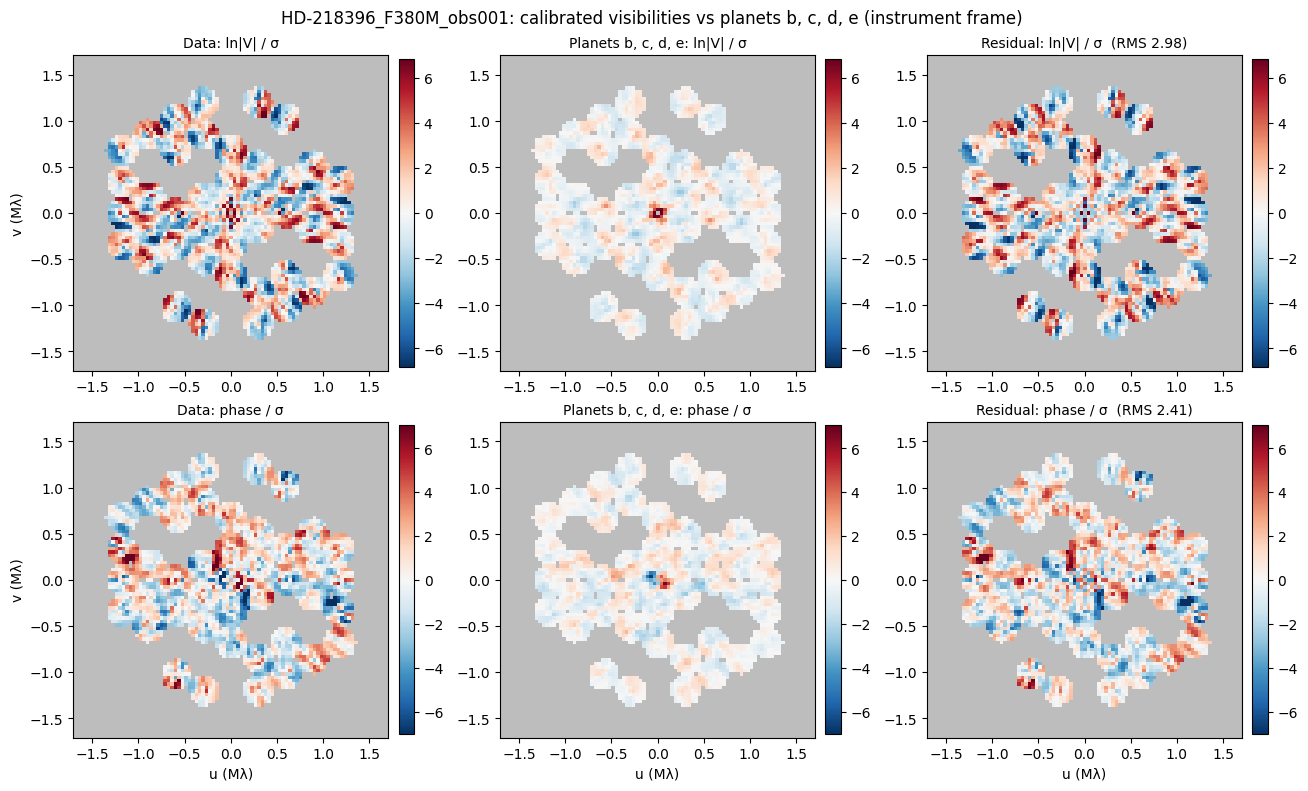

In [21]:
for name, (detected, fit) in free.items():
    pipeline_plots.uv_model_comparison(
        output_path,
        name,
        discos[name],
        scene(fit["x"]),
        label=f"planets {', '.join(detected)}",
    )
    plt.show()